(busqueda-prisma)=
# 8.10. Búsqueda sistemática y flujo PRISMA

La búsqueda complementaria declarada el 25 de noviembre de 2026 reúne 3.176 registros de Scopus, Web of Science e IEEE Xplore. El inventario permite conciliar las etapas de selección y examinar las menciones de familias neuronales en los resúmenes. Este análisis complementa la {ref}`extracción verificada en texto completo <frecuencia-comparadores>`, cuyo denominador se mantiene separado.

El flujo sigue la estructura de identificación y selección de PRISMA 2020 {cite:p}`prisma2020`. Se presentan las etapas realizadas; los candidatos seleccionados por resumen no se contabilizan como textos completos evaluados.

## Estrategia de búsqueda

El anexo declara consultas el mismo día con las siguientes cadenas: el término de demanda o carga en el título, una familia de aprendizaje profundo, el corto plazo y el lenguaje de comparación en título, resumen o palabras clave. El periodo de publicación considerado es 2018–2026.

| Base | Fecha declarada | Registros reportados | Filtros |
|---|---|---|---|
| Scopus | 2026-11-25 | 1.619 | Artículos y ponencias; inglés y español; 2018–2026 |
| Web of Science Core Collection | 2026-11-25 | 873 | 2018–2026 en la cadena |
| IEEE Xplore | 2026-11-25 | 684 | Sin filtro de años en la exportación; se retiran 132 registros anteriores a 2018 |
| Otros métodos | 2026-11-07 y 2026-11-08 | 6 | Búsqueda pública y textos completos ya revisados en este capítulo |

**Scopus (Advanced search)**

```text
TITLE ( "load forecasting" OR "load forecast" OR "electricity demand forecasting" OR "electricity demand forecast" OR "electric load forecasting" OR "power demand forecasting" OR "power load forecasting" )
AND TITLE-ABS-KEY ( "deep learning" OR "neural network*" OR lstm OR cnn OR "convolutional" OR transformer OR "temporal convolutional" OR mlp )
AND TITLE-ABS-KEY ( "short-term" OR "day-ahead" OR "day ahead" OR hourly OR "24-hour" )
AND TITLE-ABS-KEY ( comparison OR comparative OR benchmark OR "compared with" OR baseline* )
AND PUBYEAR > 2017 AND PUBYEAR < 2027
AND ( LIMIT-TO ( DOCTYPE , "ar" ) OR LIMIT-TO ( DOCTYPE , "cp" ) )
AND ( LIMIT-TO ( LANGUAGE , "English" ) OR LIMIT-TO ( LANGUAGE , "Spanish" ) )
```

**Web of Science (Advanced search)**

```text
TI=("load forecasting" OR "load forecast" OR "electricity demand forecasting" OR "electricity demand forecast" OR "electric load forecasting" OR "power demand forecasting" OR "power load forecasting")
AND TS=("deep learning" OR "neural network*" OR LSTM OR CNN OR convolutional OR transformer OR "temporal convolutional" OR MLP)
AND TS=("short-term" OR "day-ahead" OR "day ahead" OR hourly OR "24-hour")
AND TS=(comparison OR comparative OR benchmark OR "compared with" OR baseline*)
AND PY=(2018-2026)
```

**IEEE Xplore (Command search)**

```text
("Document Title":"load forecasting" OR "Document Title":"load forecast" OR "Document Title":"electricity demand forecasting" OR "Document Title":"power demand forecasting")
AND ("All Metadata":"deep learning" OR "All Metadata":"neural network" OR "All Metadata":LSTM OR "All Metadata":CNN OR "All Metadata":transformer)
AND ("All Metadata":"short-term" OR "All Metadata":"day-ahead" OR "All Metadata":hourly)
AND ("All Metadata":comparison OR "All Metadata":benchmark OR "All Metadata":comparative)
```

Scopus superó el umbral de 1.500 registros previsto en el protocolo para acotar la cadena; se conservó completa y la decisión quedó registrada. Se conservan 11 registros catalogados como 2027 que el anexo identifica como acceso anticipado de 2026; esa fecha editorial no se verifica con las exportaciones disponibles.

Las cadenas de Scopus y Web of Science figuran «Por confirmar» en el registro original de ejecución. Las exportaciones del nuevo corpus no acompañan el anexo. Los archivos de la carpeta de resúmenes disponible pertenecen a las consultas de comienzos de noviembre y no se utilizan para acreditar esta ejecución. Se conserva la {download}`versión original del protocolo <_static/literature/prisma/PROTOCOLO_BUSQUEDA_20261125.md>` y la {download}`enmienda de integración <_static/literature/prisma/PROTOCOLO_BUSQUEDA.md>`.

## Criterios de elegibilidad

| Código | Criterio de inclusión | Motivo de exclusión |
|---|---|---|
| I1 / E1 | El objetivo es demanda o carga eléctrica agregada (sistema, región, red de distribución) | Otro dominio, otra variable o un único edificio, hogar, consumidor o instalación |
| I2 / E2 | Horizonte de corto plazo, de hasta siete días | Horizonte mediano o largo |
| I3 / E3 | Al menos un modelo neuronal evaluado | Sin modelo neuronal |
| I4b / E4 | El cribado original detecta al menos dos grupos neuronales en frases comparativas y menciona resultados de error | Sin comparación entre familias o sin métricas |
| I5 / E5 | Estudio primario | Revisión o estado del arte |
| — / E7 | — | Publicación retractada |

El extractor original agrupa MLP, ANN, DNN, BP, ELM y RBF; ese grupo se denomina aquí «Redes densas y afines». CNN no especifica dimensión, y N-BEATS y N-HiTS comparten grupo. La eliminación automática de nombres híbridos no distingue si corresponden al método propuesto o a un comparador. El criterio I4b se fijó por enmienda antes de cualquier lectura de texto completo, cuando la primera pasada dejó 1.509 registros; responde directamente a la pregunta de esta revisión: qué modelos neuronales se usan como referencia.

## Selección, trazabilidad y control de extracción

El anexo conserva un cribado asistido por IA en dos pasadas: título/tipo de documento y resumen. Las decisiones están identificadas por registro. El flujo reproduce esas decisiones originales y no las interpreta como un doble cribado humano independiente.

La regla de resumen detecta familias en oraciones comparativas. Puede incluir la arquitectura propuesta y omitir comparadores híbridos o no mencionados en el resumen. Por ello, las frecuencias son señales de identificación, no una extracción confirmada de uso como baseline. El control interno declarado de 28 decisiones, con 24 consideradas correctas antes de modificar patrones, no dispone de una muestra aleatoria ni de adjudicaciones independientes documentadas.

La [regla corregida](_static/literature/prisma/cribado_resumen_corregido.py) identifica cláusulas que nombran referencias, conserva los comparadores híbridos sin descomponerlos y separa MLP, ANN/DNN, ELM, RBF, N-BEATS y N-HiTS. Los casos ambiguos quedan pendientes de revisión. Su reaplicación al corpus requiere las exportaciones con resúmenes; no se asignan nuevos conteos sin esos datos.

In [5]:
from pathlib import Path  # Rutas portables
import json  # Lectura de los conteos de identificación
import pandas as pd  # Tablas de registros
import matplotlib.pyplot as plt  # Interfaz de figuras
from matplotlib.patches import FancyBboxPatch  # Cajas redondeadas del diagrama
from IPython.display import display  # Muestra tablas en el libro
D = next(c for p in [Path.cwd(), *Path.cwd().parents] for c in (p/'_static/literature/prisma', p/'book/_static/literature/prisma') if c.exists())  # Carpeta de datos publicada
ident = json.loads((D/'identificacion.json').read_text(encoding='utf-8'))  # Conteos por base y fuera de periodo
reg = pd.read_csv(D/'registros_cribado.csv', dtype=str).fillna('')  # Decisiones registro por registro (sin resúmenes)
bases = reg[reg['via'] == 'bases']  # Registros de Scopus, WoS e IEEE
otros = reg[reg['via'] == 'otros']  # Registros hallados solo por otros métodos
exportados = sum(ident['por_base'].values())  # Registros exportados de las tres bases
fuera = sum(ident['fuera_periodo'].values())  # Anteriores a 2018
duplicados = exportados - fuera - len(bases)  # Duplicados dentro y entre bases
excl_ti = bases[bases['ia_decision'] == 'excluir']  # Excluidos por título
pasa_ti = bases[bases['ia_decision'] == 'incluir']  # Pasan a resumen
excl_ab = pasa_ti[pasa_ti['ia_resumen_decision'] == 'excluir']  # Excluidos por resumen
incl_ab = pasa_ti[pasa_ti['ia_resumen_decision'] == 'incluir']  # Elegibles por resumen
flujo = pd.DataFrame([  # Tabla del flujo
    ('Registros exportados (Scopus, WoS, IEEE)', exportados),  # Identificación
    ('Anteriores a 2018 (IEEE sin filtro de años)', fuera),  # Retirados antes del cribado
    ('Duplicados dentro y entre bases', duplicados),  # Retirados antes del cribado
    ('Registros cribados por título', len(bases)),  # Primera pasada
    ('Excluidos por título', len(excl_ti)),  # Primera pasada
    ('Registros cribados por resumen', len(pasa_ti)),  # Segunda pasada
    ('Excluidos por resumen', len(excl_ab)),  # Segunda pasada
    ('Elegibles por resumen (bases)', len(incl_ab)),  # Resultado de las bases
    ('Identificados por otros métodos', ident['otros_metodos']),  # Otra vía
    ('De ellos, ya presentes en las bases', ident['otros_metodos'] - len(otros)),  # Coincidencias
], columns=['etapa', 'registros'])  # Columnas
assert len(bases) == 1910 and len(incl_ab) == 248
assert exportados - fuera - duplicados == len(bases)
assert len(excl_ti) + len(excl_ab) + len(incl_ab) == len(bases)

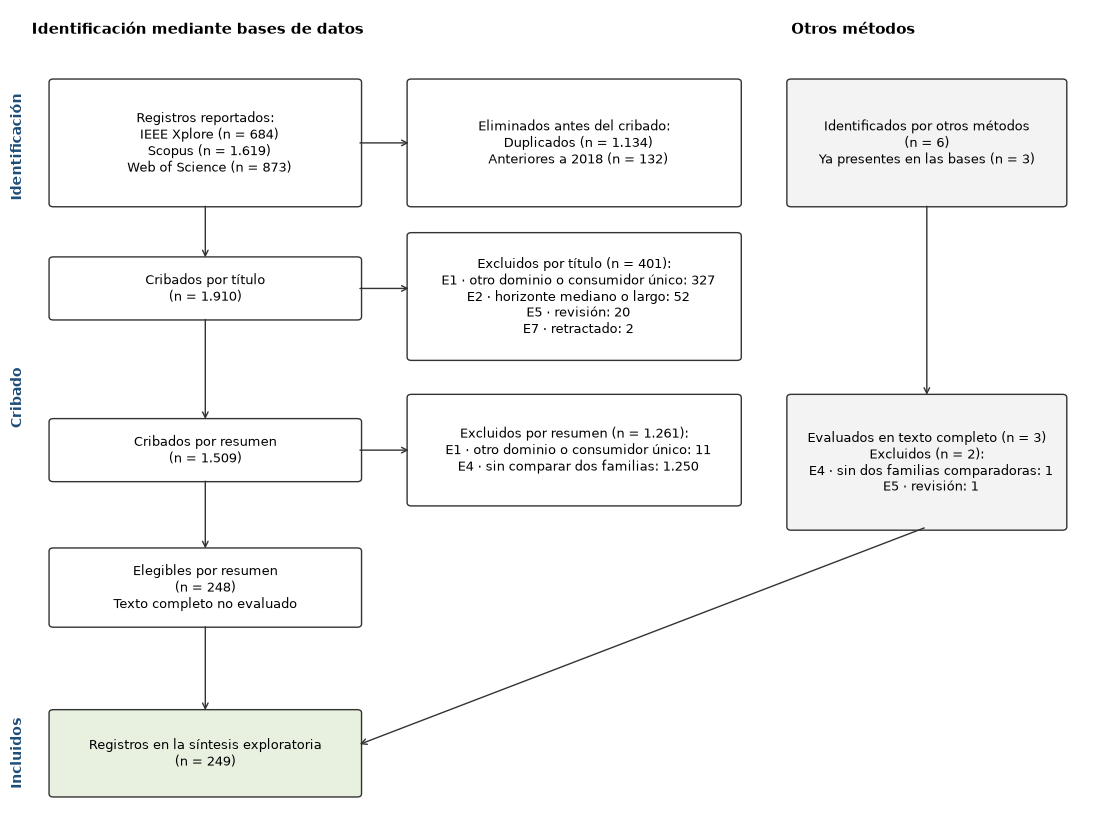

In [6]:
motivos = {'E1': 'otro dominio o consumidor único', 'E2': 'horizonte mediano o largo', 'E4': 'sin comparar dos familias', 'E5': 'revisión', 'E7': 'retractado'}  # Texto de cada código
m_ti = excl_ti['ia_motivo'].value_counts().sort_index()  # Exclusiones por título y motivo
m_ab = excl_ab['ia_resumen_motivo'].value_counts().sort_index()  # Exclusiones por resumen y motivo
tc_otros = pd.DataFrame({'estudio': ['Laitsos et al. (2023)', 'Bai et al. (2024), News and Load', 'Nti et al. (2020)'], 'decision': ['incluido', 'excluido', 'excluido'], 'motivo': ['', 'E4: no se acreditan dos familias neuronales como comparadores', 'E5: revisión']})  # Evaluación en texto completo de los registros de otros métodos (sección 8.2)
incl_otros = int((tc_otros['decision'] == 'incluido').sum())  # Incluidos por otros métodos
f = lambda n: f'{n:,}'.replace(',', '.')  # Miles con punto
lin = lambda s: '\n'.join(f'  {k} · {motivos[k]}: {f(v)}' for k, v in s.items())  # Texto de motivos para las cajas
fig, ax = plt.subplots(figsize=(14, 10.5))  # Lienzo del diagrama
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis('off')  # Coordenadas y sin ejes
def caja(x, y, w, h, t, c='#ffffff'):  # Caja con texto centrado
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.4', fc=c, ec='#333333', lw=1))  # Rectángulo
    ax.text(x + w/2, y + h/2, t, ha='center', va='center', fontsize=9)  # Texto
def flecha(x1, y1, x2, y2):  # Flecha entre dos puntos
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->', color='#333333'))  # Dibujo
ax.text(2, 97, 'Identificación mediante bases de datos', fontsize=11, weight='bold')  # Encabezado izquierdo
ax.text(72, 97, 'Otros métodos', fontsize=11, weight='bold')  # Encabezado derecho
for y, t in [(83, 'Identificación'), (52, 'Cribado'), (8, 'Incluidos')]:  # Etiquetas de fase
    ax.text(0, y, t, rotation=90, va='center', fontsize=10, weight='bold', color='#1f4e79')  # Texto vertical
caja(4, 76, 28, 15, 'Registros reportados:\n' + '\n'.join(f'  {k} (n = {f(v)})' for k, v in ident['por_base'].items()))  # Por base
caja(37, 76, 30, 15, f'Eliminados antes del cribado:\n  Duplicados (n = {f(duplicados)})\n  Anteriores a 2018 (n = {fuera})')  # Retirados
flecha(32, 83.5, 37, 83.5); flecha(18, 76, 18, 69)  # Flechas de identificación
caja(4, 62, 28, 7, f'Cribados por título\n(n = {f(len(bases))})')  # Primera pasada
caja(37, 57, 30, 15, f'Excluidos por título (n = {len(excl_ti)}):\n' + lin(m_ti))  # Exclusiones por título
flecha(32, 65.5, 37, 65.5); flecha(18, 62, 18, 49)  # Flechas
caja(4, 42, 28, 7, f'Cribados por resumen\n(n = {f(len(pasa_ti))})')  # Segunda pasada
caja(37, 39, 30, 13, f'Excluidos por resumen (n = {f(len(excl_ab))}):\n' + lin(m_ab))  # Exclusiones por resumen
flecha(32, 45.5, 37, 45.5); flecha(18, 42, 18, 33)  # Flechas
caja(4, 24, 28, 9, f'Elegibles por resumen\n(n = {len(incl_ab)})\nTexto completo no evaluado')  # Elegibles
caja(72, 76, 25, 15, f'Identificados por otros métodos\n(n = {ident["otros_metodos"]})\nYa presentes en las bases (n = {ident["otros_metodos"] - len(otros)})', '#f3f3f3')  # Otros métodos
flecha(84.5, 76, 84.5, 52)  # Flecha a evaluación
caja(72, 36, 25, 16, f'Evaluados en texto completo (n = {len(otros)})\nExcluidos (n = {len(otros) - incl_otros}):\n  E4 · sin dos familias comparadoras: 1\n  E5 · revisión: 1', '#f3f3f3')  # Evaluación de otros
caja(4, 3, 28, 10, f'Registros en la síntesis exploratoria\n(n = {len(incl_ab) + incl_otros})', '#e8f0e0')  # Incluidos
flecha(18, 24, 18, 13); flecha(84.5, 36, 32, 9)  # Flechas a incluidos
display(fig); plt.close(fig)  # Muestra el diagrama

El flujo concilia 3.176 registros reportados, 132 anteriores al periodo y 1.134 duplicados, hasta 1.910 registros únicos de las bases. Tras 401 exclusiones por título y 1.261 por resumen quedan 248 candidatos. Los otros métodos aportan un estudio adicional a la síntesis exploratoria. No se ha evaluado el texto completo de los 248 candidatos de las bases.

En *News and Load*, la exclusión de esta síntesis se asocia a I4b/E4 —no acreditar dos familias neuronales como comparadores— y no a la ausencia de un modelo neuronal. El artículo permanece en la síntesis temática del capítulo 8 por su pertinencia para demanda y texto.

**Decisión.** Utilizar el flujo para documentar la búsqueda complementaria y orientar la revisión. **Impacto.** Amplía la trazabilidad por base y por registro. **Riesgo.** Las decisiones originales no acreditan por sí solas elegibilidad de texto completo ni roles de comparador.

## Familias identificadas automáticamente en los resúmenes

La unidad es el par registro–grupo: cada registro cuenta una vez por grupo detectado. Se agregan los comparadores extraídos del texto completo de Laitsos et al. Los 249 registros del gráfico combinan 248 candidatos por resumen con ese estudio; el gráfico no sustituye la frecuencia verificada de cinco textos completos del apartado 8.5.

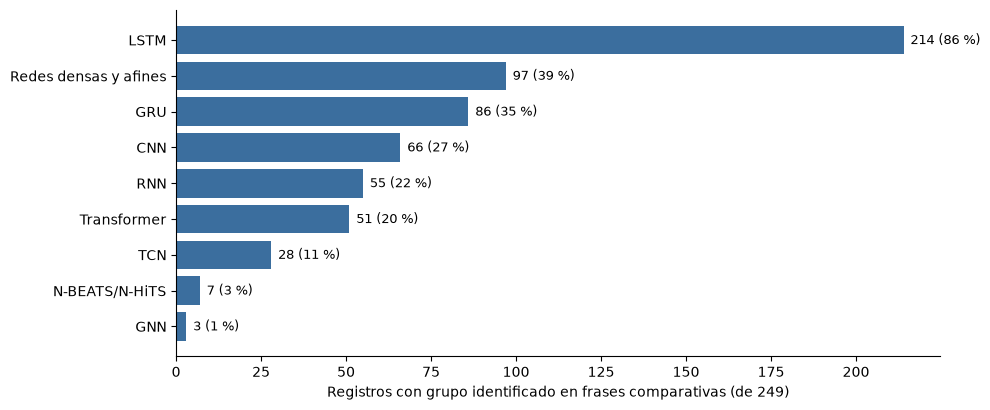

In [9]:
fam = incl_ab['ia_familias'].str.split(';').explode()  # Familias por estudio en las bases
fam = pd.concat([fam, pd.Series(['MLP', 'LSTM', 'CNN', 'TCN'])])  # Laitsos et al. (2023): MLP, LSTM, CNN1D y TCN como comparadores (8.2)
n = len(incl_ab) + incl_otros  # Estudios en la síntesis
fam = fam.replace({'MLP':'Redes densas y afines','NBEATS':'N-BEATS/N-HiTS'})
frec = fam.value_counts().rename('estudios').to_frame()  # Estudios por familia
frec['porcentaje'] = (100 * frec['estudios'] / n).round(1)  # Porcentaje sobre los estudios incluidos
frec.index.name = 'familia'  # Nombre del índice
assert n == 249  # Denominador conciliado; no equivale a249textos completos
fig, ax = plt.subplots(figsize=(10, 4.2))  # Lienzo
ax.barh(frec.index[::-1], frec['estudios'][::-1], color='#3b6e9e')  # Barras horizontales
for i, v in enumerate(frec['estudios'][::-1]):  # Etiqueta de cada barra
    ax.text(v + 2, i, f'{v} ({100*v/n:.0f} %)', va='center', fontsize=9)  # Valor y porcentaje
ax.set_xlabel(f'Registros con grupo identificado en frases comparativas (de {n})')  # Eje x
ax.spines[['top', 'right']].set_visible(False)  # Ejes limpios
plt.tight_layout(); display(fig); plt.close(fig)  # Muestra la figura

La extracción original identifica LSTM en 214 registros, redes densas y afines en 97, GRU en 86 y CNN en 66. La agrupación amplia impide interpretar los 97 casos como frecuencia específica de MLP. Tampoco se atribuye dimensión 1D a las CNN identificadas solo por nombre.

La selección de MLP, LSTM y CNN1D se fundamenta en los textos completos y en la diversidad de sus mecanismos, según 8.5–8.6. Esta ampliación permite localizar candidatos para verificar esa evidencia; no reconstruye una selección prospectiva anterior a los experimentos.

## Calidad de tres estudios de comparación revisados en texto completo

La valoración se aplica a los tres estudios de comparación neuronal leídos en texto completo (8.2). NR indica que el aspecto no se reportó en las secciones extraídas.

| Estudio | Protocolo experimental | Riesgo de fuga | Repeticiones | Pruebas estadísticas |
|---|---|---|---|---|
| [Pelekis et al. (2023)](https://doi.org/10.1016/j.segan.2023.101171) | Claro: entrenamiento 2013–2019, validación 2020, prueba 2021 | Medio: temperatura observada ex post, sin pronóstico meteorológico disponible al origen | 100 ensayos de búsqueda y ensamble mediano de 30 redes | NR |
| [Kathirgamanathan et al. (2022)](https://doi.org/10.1049/tje2.12132) | Parcial: ajuste 2004–2007 y prueba 2009; la descripción de la CNN1D no coincide del todo con su tabla | Partición temporal; ajuste del escalado NR | NR | NR |
| [Laitsos et al. (2023)](https://doi.org/10.3390/math11132912) | Claro: datos horarios 2017–2019, últimos tres meses de prueba | Por verificar: no consta que el Min–Max se ajuste solo con entrenamiento | 20 iteraciones de optimización; sin varias semillas | NR |

Las extracciones no registran pruebas de significancia entre modelos ni intervalos entre semillas en ninguno de los tres. Las repeticiones y la inferencia formal de este estudio cubren esa carencia.

## Alcance y archivos de reproducción

El inventario público permite reconstruir las figuras y los conteos; las exportaciones originales son necesarias para reaplicar la regla corregida. La matriz de calidad cubre los tres estudios revisados en texto completo de esta sección, no los 249 registros de la síntesis exploratoria.

{download}`Protocolo y enmiendas <_static/literature/prisma/PROTOCOLO_BUSQUEDA.md>` · [Decisiones por registro](_static/literature/prisma/registros_cribado.csv) · [Conteos de identificación](_static/literature/prisma/identificacion.json) · [Otros métodos](_static/literature/prisma/otras_fuentes.csv).

```{literalinclude} _static/literature/prisma/cribado_resumen_corregido.py
:language: python
```

[Regla de título original](_static/literature/prisma/cribado_ia.py) · [Decisiones leídas por el asistente](_static/literature/prisma/cribado_ia_manual.csv) · [Regla de resumen original](_static/literature/prisma/cribado_resumen.py) · [Unión de exportaciones](_static/literature/prisma/prisma.py).

Las exportaciones con resúmenes se mantienen fuera de los recursos públicos. La lista de decisiones permite comprobar las cifras publicadas, pero no sustituye la documentación de los registros completos.